/tmp/ipykernel_866/2703983912.py:39: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = df[label_col].replace(
/tmp/ipykernel_866/2703983912.py:39: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = df[label_col].replace(
/tmp/ipykernel_866/2703983912.py:39: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y

Client-1: Train=195, Test=49
Client-2: Train=134, Test=34
Client-3: Train=145, Test=37

🔄 FL Round 1

🔄 FL Round 2

🔄 FL Round 3

🔄 FL Round 4

🔄 FL Round 5

🔄 FL Round 6

🔄 FL Round 7

🔄 FL Round 8

🔄 FL Round 9

🔄 FL Round 10

🔄 FL Round 11

🔄 FL Round 12

🔄 FL Round 13

🔄 FL Round 14

🔄 FL Round 15

🔄 FL Round 16

🔄 FL Round 17

🔄 FL Round 18

🔄 FL Round 19

🔄 FL Round 20

🔄 FL Round 21

🔄 FL Round 22

🔄 FL Round 23

🔄 FL Round 24

🔄 FL Round 25

🔄 FL Round 26

🔄 FL Round 27

🔄 FL Round 28

🔄 FL Round 29

🔄 FL Round 30

🔄 FL Round 31

🔄 FL Round 32

🔄 FL Round 33

🔄 FL Round 34

🔄 FL Round 35

Client-1 FINAL TEST METRICS: {'Accuracy': 0.8571428571428571, 'Precision': 0.92, 'Recall': 0.8214285714285714, 'F1': 0.8679245283018868, 'ROC-AUC': np.float64(0.9064625850340136)}

Client-2 FINAL TEST METRICS: {'Accuracy': 0.8823529411764706, 'Precision': 0.8095238095238095, 'Recall': 1.0, 'F1': 0.8947368421052632, 'ROC-AUC': np.float64(0.9826989619377162)}

Client-3 FINAL TEST METRICS: {'Accu

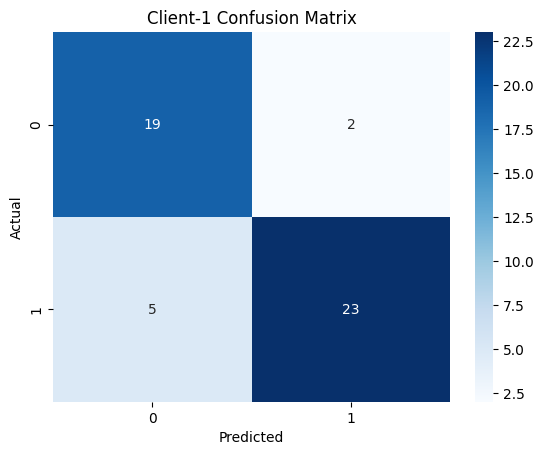

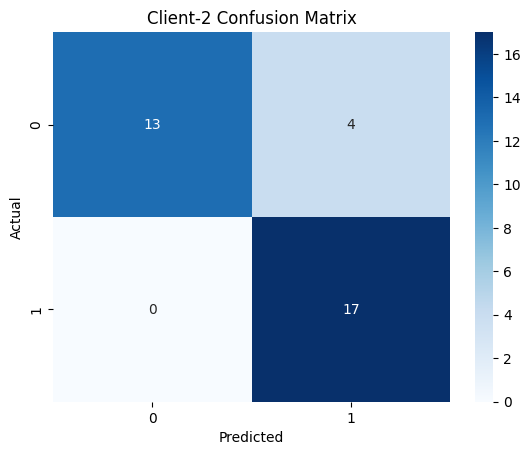

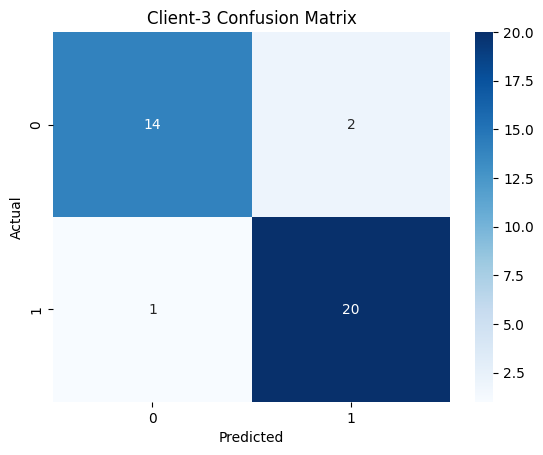

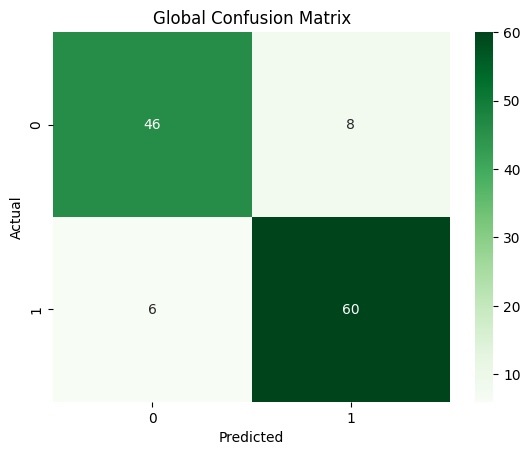

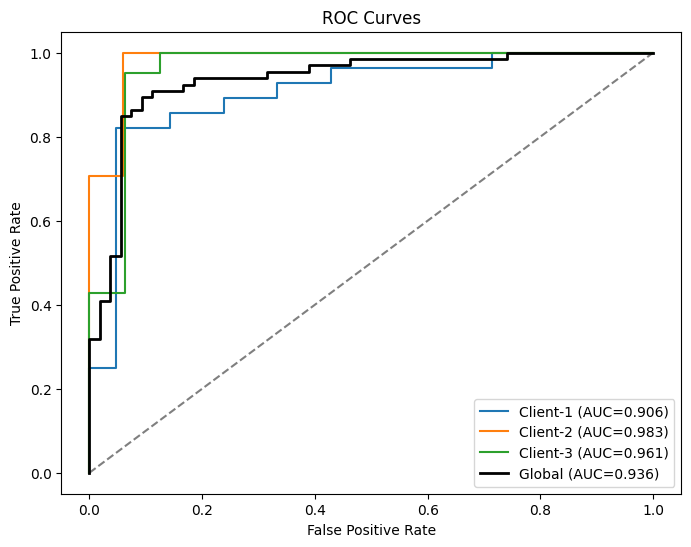

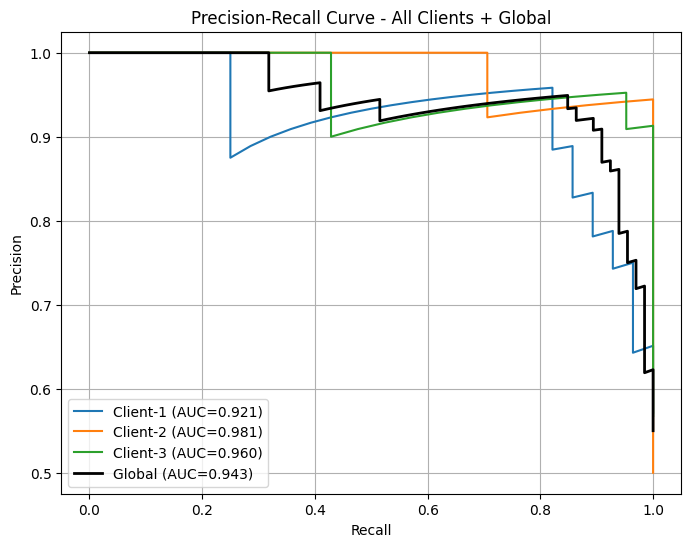

In [ ]:
# ======================================
# 1️⃣ IMPORTS
# ======================================
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, precision_recall_curve, auc
)
import matplotlib.pyplot as plt
import seaborn as sns
from copy import deepcopy

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"

# ======================================
# 2️⃣ DATA LOADING
# ======================================
paths = [
    "/content/drive/MyDrive/six datasets with common genes/GSE183795_common_genes.csv",
    "/content/drive/MyDrive/Updated Mergred datasets/Merged_GSE28735_GSE15471.csv",
    "/content/drive/MyDrive/Updated Mergred datasets/Merged_GSE62452_GSE16515.csv"
]

dfs = [pd.read_csv(p, low_memory=False) for p in paths]

clients_df, clients_y = [], []
for df in dfs:
    label_col = [c for c in df.columns if c.lower() == "label"][0]
    y = df[label_col].replace(
        {"Tumor":1, "tumor":1, "TCGA":1, "Normal":0, "normal":0, "GTEx":0, "non-tumor":0}
    ).astype(np.float32).values
    X = df.drop(columns=[label_col]).select_dtypes(include=[np.number])
    clients_df.append(X)
    clients_y.append(y)

# Keep only common genes
genes = set(clients_df[0].columns)
for df in clients_df[1:]:
    genes &= set(df.columns)
genes = sorted(list(genes))
clients_df = [df[genes] for df in clients_df]

# Remove NaNs
clean_X, clean_y = [], []
for X, y in zip(clients_df, clients_y):
    mask = np.isnan(X.values).any(axis=1)
    clean_X.append(X.loc[~mask])
    clean_y.append(y[~mask])
clients_df, clients_y = clean_X, clean_y

# Scale features
scaler = StandardScaler()
X_all = scaler.fit_transform(pd.concat(clients_df))
clients_X = [scaler.transform(df).astype(np.float32) for df in clients_df]

# ======================================
# 3️⃣ TRAIN-TEST SPLIT
# ======================================
clients_train, clients_test = [], []
for i, (X, y) in enumerate(zip(clients_X, clients_y)):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    clients_train.append((Xtr, ytr))
    clients_test.append((Xte, yte))
    print(f"Client-{i+1}: Train={len(ytr)}, Test={len(yte)}")

# ======================================
# 4️⃣ DEFINE MLP MODEL
# ======================================
class MLP(nn.Module):
    def __init__(self, input_dim):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        x = torch.sigmoid(self.fc3(x))
        return x

# ======================================
# 5️⃣ FEDERATED LEARNING SETUP
# ======================================
ROUNDS = 35
EPOCHS = 10
BATCH_SIZE = 32
LR = 1e-3

clients_models = [MLP(clients_train[i][0].shape[1]).to(device) for i in range(len(clients_train))]
criterion = nn.BCELoss()

for r in range(ROUNDS):
    print(f"\n🔄 FL Round {r+1}")
    weights_list = []

    for i, model in enumerate(clients_models):
        model.train()
        optimizer = torch.optim.Adam(model.parameters(), lr=LR)
        Xtr, ytr = clients_train[i]
        dataset = TensorDataset(torch.tensor(Xtr), torch.tensor(ytr))
        loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

        for epoch in range(EPOCHS):
            for xb, yb in loader:
                xb, yb = xb.to(device), yb.to(device).unsqueeze(1)
                optimizer.zero_grad()
                y_pred = model(xb)
                loss = criterion(y_pred, yb)
                loss.backward()
                optimizer.step()
        weights_list.append(deepcopy(model.state_dict()))

    # FedAvg
    global_state_dict = {}
    for key in weights_list[0].keys():
        global_state_dict[key] = torch.stack([w[key] for w in weights_list]).mean(dim=0)

    # Update clients
    for model in clients_models:
        model.load_state_dict(global_state_dict)

# ======================================
# 6️⃣ EVALUATION
# ======================================
def evaluate_model(model, X, y, threshold=0.5):
    model.eval()
    with torch.no_grad():
        X_t = torch.tensor(X).to(device)
        y_prob = model(X_t).cpu().numpy().flatten()
        y_pred = (y_prob >= threshold).astype(int)
    acc = accuracy_score(y, y_pred)
    prec = precision_score(y, y_pred, zero_division=0)
    rec = recall_score(y, y_pred, zero_division=0)
    f1 = f1_score(y, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y, y_prob)
    return y_pred, y_prob, {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1, "ROC-AUC": roc_auc}

all_y_true, all_y_pred, all_y_prob = [], [], []

for i, (Xte, yte) in enumerate(clients_test):
    y_pred, y_prob, metrics = evaluate_model(clients_models[i], Xte, yte)
    all_y_true.append(yte)
    all_y_pred.append(y_pred)
    all_y_prob.append(y_prob)
    print(f"\nClient-{i+1} FINAL TEST METRICS:", metrics)

# Global metrics
y_global_true = np.concatenate(all_y_true)
y_global_pred = np.concatenate(all_y_pred)
y_global_prob = np.concatenate(all_y_prob)

global_metrics = {
    "Accuracy": accuracy_score(y_global_true, y_global_pred),
    "Precision": precision_score(y_global_true, y_global_pred, zero_division=0),
    "Recall": recall_score(y_global_true, y_global_pred, zero_division=0),
    "F1": f1_score(y_global_true, y_global_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_global_true, y_global_prob)
}
print("\n🌍 GLOBAL TEST METRICS:", global_metrics)

# ======================================
# 7️⃣ PLOTS
# ======================================
# Confusion matrices
for i, (y_true, y_pred) in enumerate(zip(all_y_true, all_y_pred)):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Client-{i+1} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

cm = confusion_matrix(y_global_true, y_global_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("Global Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ROC curves
plt.figure(figsize=(8,6))
for i, (y_true, y_prob) in enumerate(zip(all_y_true, all_y_prob)):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    plt.plot(fpr, tpr, label=f"Client-{i+1} (AUC={auc(fpr,tpr):.3f})")
fpr, tpr, _ = roc_curve(y_global_true, y_global_prob)
plt.plot(fpr, tpr, label=f"Global (AUC={auc(fpr,tpr):.3f})", linewidth=2, color='black')
plt.plot([0,1],[0,1],'k--', alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

plt.figure(figsize=(8,6))

# Plot each client PR curve and annotate PR AUC
for i, (y_true, y_prob) in enumerate(zip(all_y_true, all_y_prob)):
    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(recall, precision)
    plt.plot(recall, precision, label=f"Client-{i+1} (AUC={pr_auc:.3f})")

# Plot global PR curve
precision, recall, _ = precision_recall_curve(y_global_true, y_global_prob)
pr_auc_global = auc(recall, precision)
plt.plot(recall, precision, label=f"Global (AUC={pr_auc_global:.3f})", linewidth=2, color='black')

# Labels, title, legend
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - All Clients + Global")
plt.legend(loc="lower left")
plt.grid(True)
plt.show()

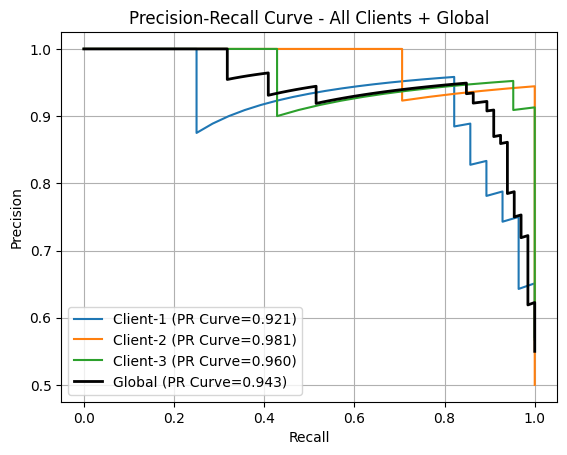

In [ ]:
# Plot each client PR curve and annotate PR AUC
for i, (y_true, y_prob) in enumerate(zip(all_y_true, all_y_prob)):
    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(recall, precision)
    plt.plot(recall, precision, label=f"Client-{i+1} (PR Curve={pr_auc:.3f})")

# Plot global PR curve
precision, recall, _ = precision_recall_curve(y_global_true, y_global_prob)
pr_auc_global = auc(recall, precision)
plt.plot(recall, precision, label=f"Global (PR Curve={pr_auc_global:.3f})", linewidth=2, color='black')

# Labels, title, legend
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - All Clients + Global")
plt.legend(loc="lower left")
plt.grid(True)
plt.show()

# **SHAP**

🔹 SHAP Summary (Bar) – Global FL Model


/tmp/ipykernel_866/1919101574.py:94: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


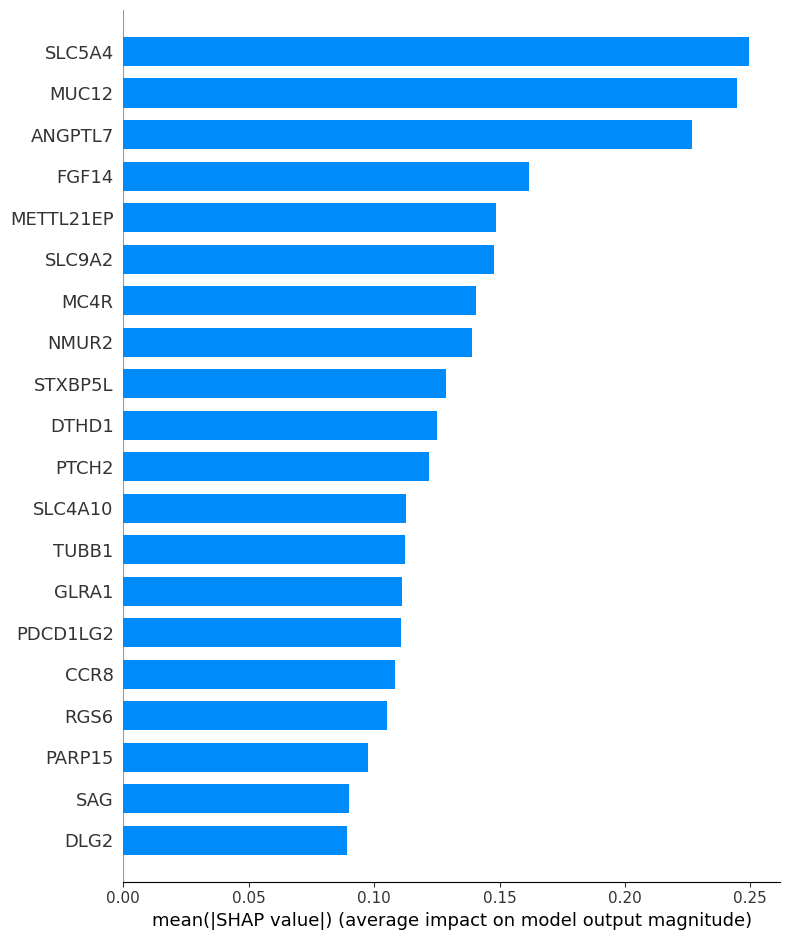

🔹 SHAP Summary (Beeswarm) – Global FL Model


/tmp/ipykernel_866/1919101574.py:108: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


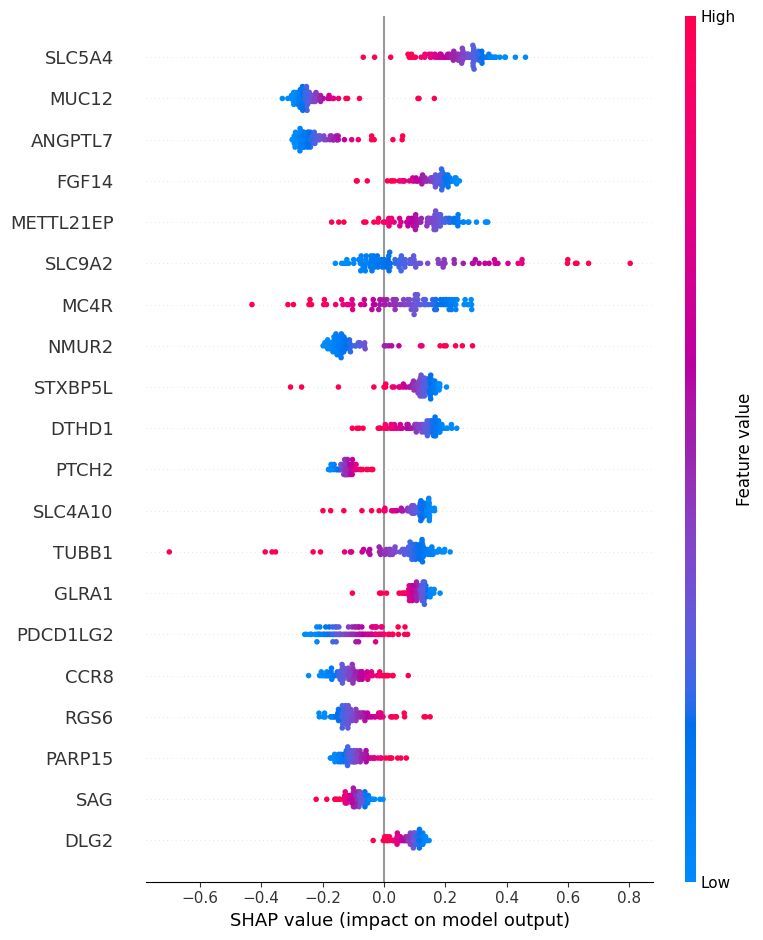

🔹 SHAP Decision Plot – Global FL Model


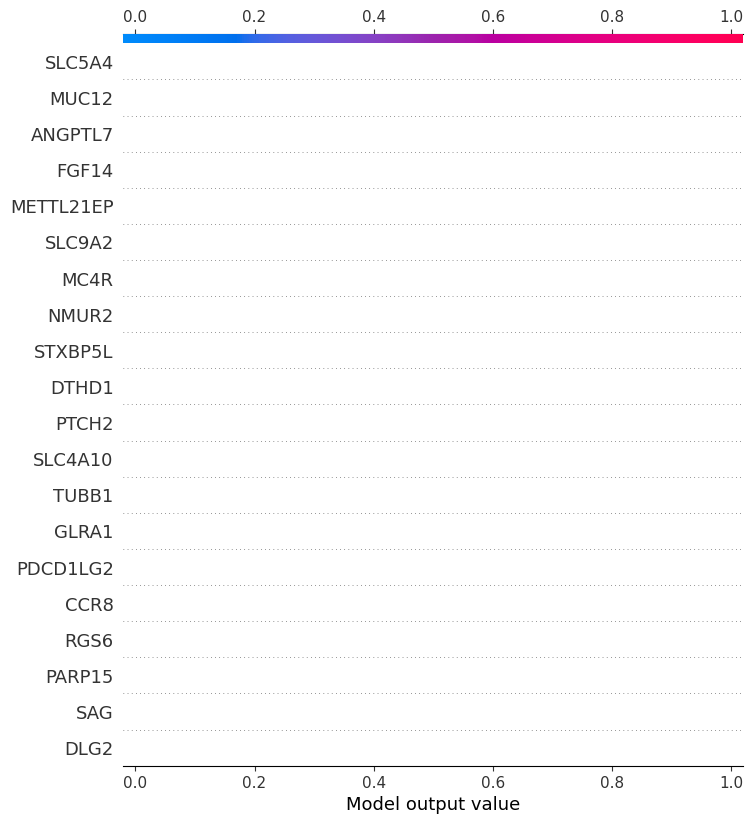

🔹 SHAP Waterfall – Sample 0


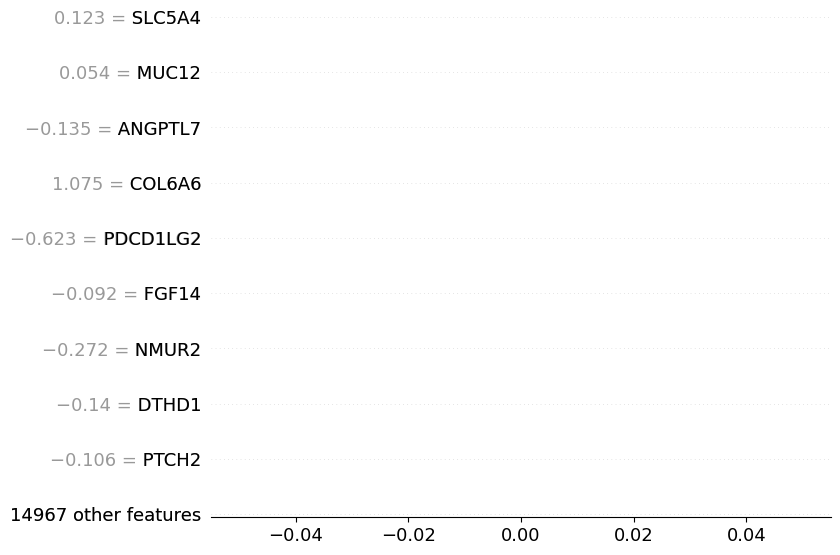

🔹 SHAP Force Plot – Sample 0


,Gene,Mean_Abs_SHAP
0,SLC5A4,0.249382
1,MUC12,0.244790
2,ANGPTL7,0.226897
3,FGF14,0.161831
4,METTL21EP,0.148481
5,SLC9A2,0.147659
6,MC4R,0.140635
7,NMUR2,0.139175
8,STXBP5L,0.128653
9,DTHD1,0.125138


In [ ]:
# ======================================
# 1️⃣ IMPORTS
# ======================================
import shap
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# Ensure eval mode
global_model = clients_models[0].to(device)
global_model.eval()

# ======================================
# 2️⃣ MODEL WRAPPER (REQUIRED FOR SHAP)
# Converts sigmoid output → 2-class logits
# ======================================
class ModelWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        prob = self.model(x)               # (N,1) sigmoid
        logit = torch.log(prob / (1 - prob + 1e-8))
        return torch.cat([-logit, logit], dim=1)

wrapped_global_model = ModelWrapper(global_model).to(device)
wrapped_global_model.eval()

# ======================================
# 3️⃣ BACKGROUND & TEST DATA
# Use GLOBAL pooled data (recommended)
# ======================================
X_all_np = np.vstack(clients_X)

background_data = torch.tensor(
    X_all_np[:100], dtype=torch.float32
).to(device)

test_data = torch.tensor(
    X_all_np[100:200], dtype=torch.float32
).to(device)

# ======================================
# 4️⃣ SHAP EXPLAINER
# ======================================
explainer = shap.DeepExplainer(
    wrapped_global_model,
    background_data
)

# ======================================
# 5️⃣ COMPUTE SHAP VALUES
# Output: (samples, features, classes)
# ======================================

shap_values = explainer.shap_values(
    test_data,
    check_additivity=False   # 🔥 FIX
)

# Positive class (Tumor = 1)
shap_vals_pos = shap_values[:, :, 1]
test_data_np = test_data.cpu().numpy()

# ======================================
# 6️⃣ GENE SYMBOL CLEANING
# ======================================
def is_gene_symbol(name):
    name = str(name)
    is_id = bool(re.fullmatch(r'ENSG\d+|LOC\d+|\d+-\d+|\d+P\d+|RPL\d+P\d+', name))
    contains_alpha = bool(re.search(r'[A-Z]', name))
    return (not is_id) and contains_alpha

gene_names = np.array(genes)
valid_mask = np.array([is_gene_symbol(g) for g in gene_names])

filtered_genes = gene_names[valid_mask]
filtered_shap = shap_vals_pos[:, valid_mask]
filtered_data = test_data_np[:, valid_mask]

# ======================================
# 7️⃣ BASE VALUE (POSITIVE CLASS)
# ======================================
base_value = explainer.expected_value[1]

# ======================================
# 8️⃣ SHAP SUMMARY (BAR)
# ======================================
print("🔹 SHAP Summary (Bar) – Global FL Model")
shap.summary_plot(
    filtered_shap,
    filtered_data,
    feature_names=filtered_genes,
    plot_type="bar",
    max_display=20,
    show=False
)
plt.show()

# ======================================
# 9️⃣ SHAP SUMMARY (BEESWARM)
# ======================================
print("🔹 SHAP Summary (Beeswarm) – Global FL Model")
shap.summary_plot(
    filtered_shap,
    filtered_data,
    feature_names=filtered_genes,
    max_display=20,
    show=False
)
plt.show()

# ======================================
# 🔟 SHAP DECISION PLOT
# ======================================
print("🔹 SHAP Decision Plot – Global FL Model")
shap.decision_plot(
    base_value,
    filtered_shap,
    filtered_data,
    feature_names=filtered_genes,
    link="logit",
    show=False
)
plt.show()

# ======================================
# 1️⃣1️⃣ SHAP WATERFALL (Single Sample)
# ======================================
sample_idx = 0
print(f"🔹 SHAP Waterfall – Sample {sample_idx}")

shap.waterfall_plot(
    shap.Explanation(
        values=filtered_shap[sample_idx],
        base_values=base_value,
        data=filtered_data[sample_idx],
        feature_names=filtered_genes
    ),
    show=False
)
plt.show()

# ======================================
# 1️⃣2️⃣ SHAP FORCE PLOT (Interactive)
# ======================================
print("🔹 SHAP Force Plot – Sample 0")
shap.initjs()
shap.force_plot(
    base_value,
    filtered_shap[sample_idx],
    filtered_data[sample_idx],
    feature_names=filtered_genes
)

# ======================================
# 1️⃣3️⃣ SHAP GENE IMPORTANCE TABLE
# ======================================
mean_abs_shap = np.mean(np.abs(filtered_shap), axis=0)

shap_df = pd.DataFrame({
    "Gene": filtered_genes,
    "Mean_Abs_SHAP": mean_abs_shap
}).sort_values(
    by="Mean_Abs_SHAP",
    ascending=False
).reset_index(drop=True)

display(shap_df.head(20))

# **again**

🔹 SHAP Summary (Bar) – Global FL Model


/tmp/ipykernel_866/167514432.py:92: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


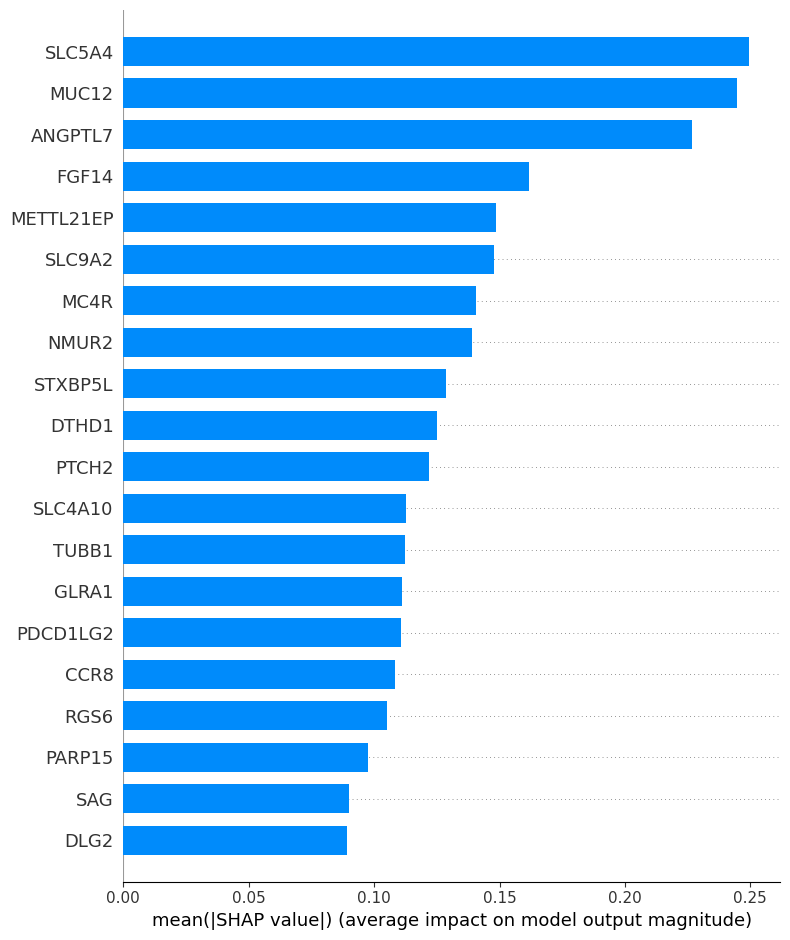

🔹 SHAP Summary (Beeswarm) – Global FL Model


/tmp/ipykernel_866/167514432.py:106: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


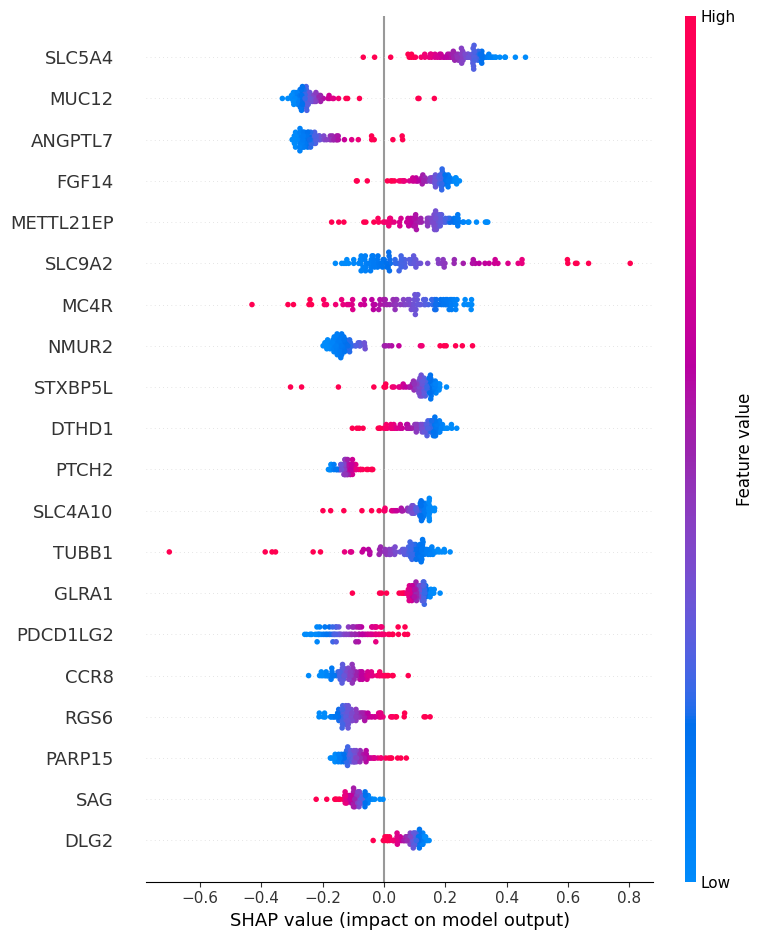

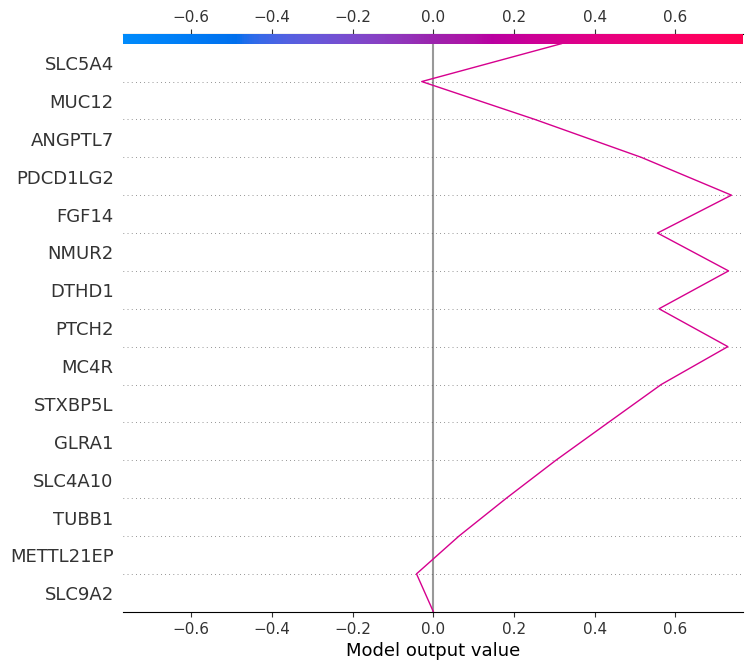

🔹 SHAP Waterfall – Sample 0


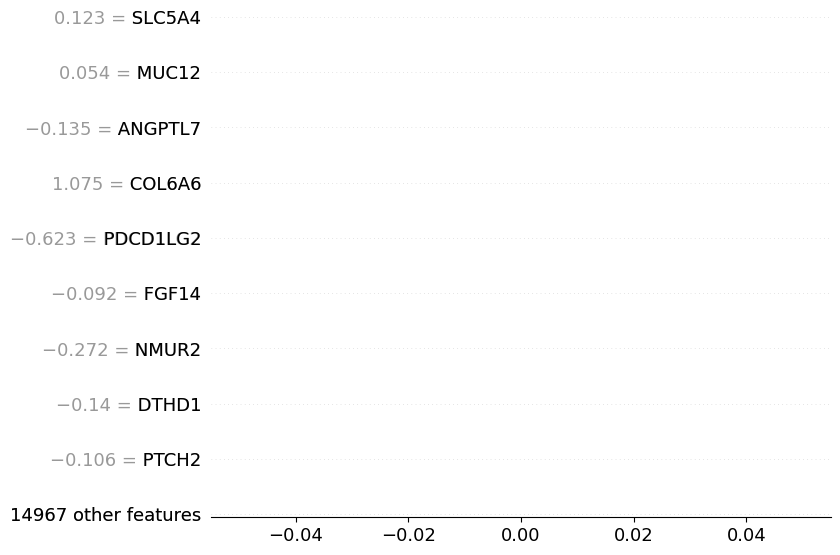

🔹 SHAP Force Plot – Sample 0


,Gene,Mean_Abs_SHAP
0,SLC5A4,0.249382
1,MUC12,0.244790
2,ANGPTL7,0.226897
3,FGF14,0.161831
4,METTL21EP,0.148481
5,SLC9A2,0.147659
6,MC4R,0.140635
7,NMUR2,0.139175
8,STXBP5L,0.128653
9,DTHD1,0.125138


In [ ]:
# ======================================
# 1️⃣ IMPORTS
# ======================================
import shap
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# Ensure eval mode
global_model = clients_models[0].to(device)
global_model.eval()

# ======================================
# 2️⃣ MODEL WRAPPER (REQUIRED FOR SHAP)
# Converts sigmoid output → 2-class logits
# ======================================
class ModelWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        prob = self.model(x)
        prob = torch.clamp(prob, 1e-5, 1 - 1e-5)  # 🔥 CRITICAL FIX
        logit = torch.log(prob / (1 - prob))
        return torch.cat([-logit, logit], dim=1)
# ======================================
# 3️⃣ BACKGROUND & TEST DATA
# ======================================
X_all_np = np.vstack(clients_X)

background_data = torch.tensor(
    X_all_np[:100], dtype=torch.float32
).to(device)

test_data = torch.tensor(
    X_all_np[100:200], dtype=torch.float32
).to(device)

# ======================================
# 4️⃣ SHAP EXPLAINER
# ======================================
explainer = shap.DeepExplainer(
    wrapped_global_model,
    background_data
)

# ======================================
# 5️⃣ COMPUTE SHAP VALUES
# Output: (samples, features, classes)
# ======================================

shap_values = explainer.shap_values(
    test_data,
    check_additivity=False   # 🔥 FIX
)

# Positive class (Tumor = 1)
shap_vals_pos = shap_values[:, :, 1]
test_data_np = test_data.cpu().numpy()

# ======================================
# 6️⃣ GENE SYMBOL CLEANING
# ======================================
def is_gene_symbol(name):
    name = str(name)
    is_id = bool(re.fullmatch(r'ENSG\d+|LOC\d+|\d+-\d+|\d+P\d+|RPL\d+P\d+', name))
    contains_alpha = bool(re.search(r'[A-Z]', name))
    return (not is_id) and contains_alpha

gene_names = np.array(genes)
valid_mask = np.array([is_gene_symbol(g) for g in gene_names])

filtered_genes = gene_names[valid_mask]
filtered_shap = shap_vals_pos[:, valid_mask]
filtered_data = test_data_np[:, valid_mask]


# 7️⃣ SAFE BASE VALUE (REQUIRED)
# ======================================
with torch.no_grad():
    bg_out = wrapped_global_model(background_data)
    base_value = bg_out[:, 1].mean().item()   # ✅ always finite
# ======================================
# 8️⃣ SHAP SUMMARY (BAR)
# ======================================
print("🔹 SHAP Summary (Bar) – Global FL Model")
shap.summary_plot(
    filtered_shap,
    filtered_data,
    feature_names=filtered_genes,
    plot_type="bar",
    max_display=20,
    show=False
)
plt.show()

# ======================================
# 9️⃣ SHAP SUMMARY (BEESWARM)
# ======================================
print("🔹 SHAP Summary (Beeswarm) – Global FL Model")
shap.summary_plot(
    filtered_shap,
    filtered_data,
    feature_names=filtered_genes,
    max_display=20,
    show=False
)
plt.show()

# Remove NaN / Inf features
mask = np.isfinite(filtered_shap).all(axis=0)

filtered_shap_clean = filtered_shap[:, mask]
filtered_data_clean = filtered_data[:, mask]
filtered_genes_clean = filtered_genes[mask]

sample_idx = 0

mean_abs_shap = np.mean(np.abs(filtered_shap_clean), axis=0)
top_idx = np.argsort(mean_abs_shap)[-15:]

# ======================================
# 🔟 SHAP DECISION PLOT
# ======================================

# ======================================
# 🔟 SHAP DECISION PLOT (GUARANTEED)
# ======================================
sample_idx = 0

# Rank features
mean_abs_shap = np.mean(np.abs(filtered_shap_clean), axis=0)
top_idx = np.argsort(mean_abs_shap)[-15:]

# Force everything to be finite
vals = np.nan_to_num(
    filtered_shap_clean[sample_idx, top_idx],
    nan=0.0, posinf=0.0, neginf=0.0
)

base_val = float(np.nan_to_num(base_value, nan=0.0, posinf=0.0, neginf=0.0))

shap.decision_plot(
    base_val,
    vals,
    feature_names=filtered_genes_clean[top_idx],
    show=False
)

plt.show()
# ======================================
# 1️⃣1️⃣ SHAP WATERFALL (Single Sample)
# ======================================
sample_idx = 0
print(f"🔹 SHAP Waterfall – Sample {sample_idx}")

shap.waterfall_plot(
    shap.Explanation(
        values=filtered_shap[sample_idx],
        base_values=base_value,
        data=filtered_data[sample_idx],
        feature_names=filtered_genes
    ),
    show=False
)
plt.show()

# ======================================
# 1️⃣2️⃣ SHAP FORCE PLOT (Interactive)
# ======================================
print("🔹 SHAP Force Plot – Sample 0")
shap.initjs()
shap.force_plot(
    base_value,
    filtered_shap[sample_idx],
    filtered_data[sample_idx],
    feature_names=filtered_genes
)

# ======================================
# 1️⃣3️⃣ SHAP GENE IMPORTANCE TABLE
# ======================================
mean_abs_shap = np.mean(np.abs(filtered_shap), axis=0)

shap_df = pd.DataFrame({
    "Gene": filtered_genes,
    "Mean_Abs_SHAP": mean_abs_shap
}).sort_values(
    by="Mean_Abs_SHAP",
    ascending=False
).reset_index(drop=True)

display(shap_df.head(20))

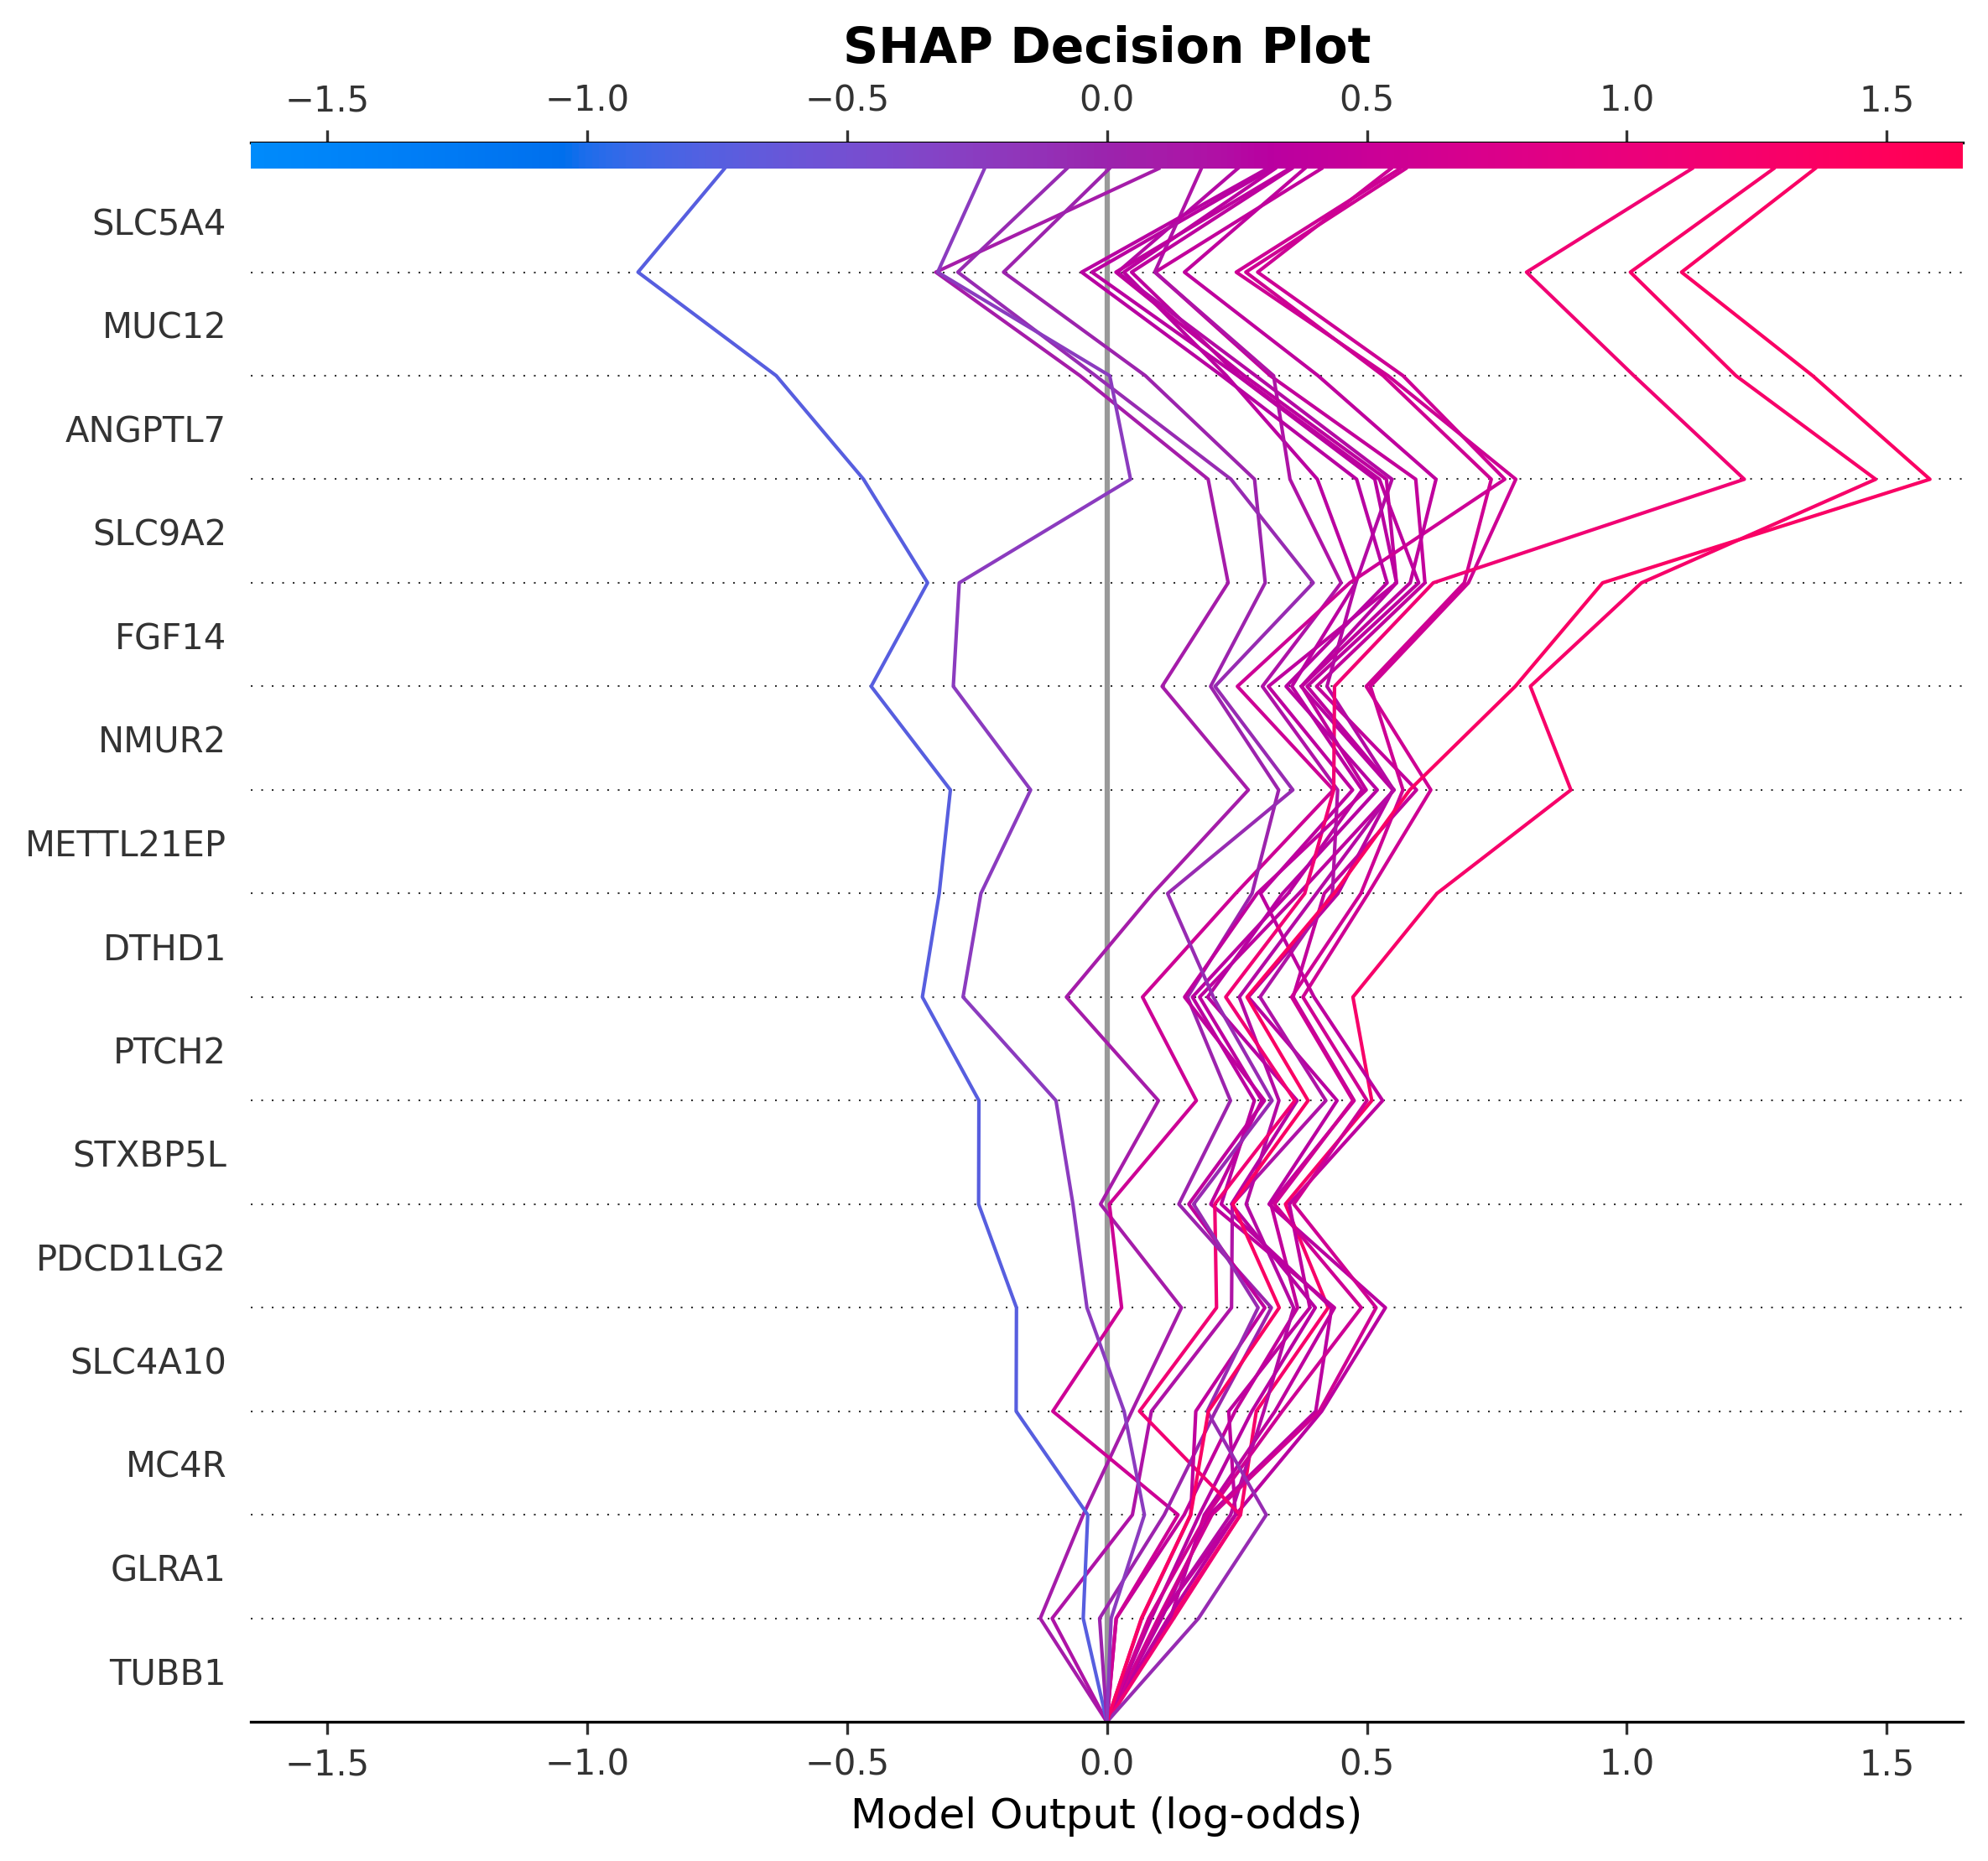

In [ ]:
# ======================================
# 📊 PUBLICATION-READY SHAP DECISION PLOT
# ======================================

import numpy as np
import matplotlib.pyplot as plt
import shap

# --------------------------------------
# 1️⃣ GLOBAL FEATURE IMPORTANCE (Top 15)
# --------------------------------------
mean_abs_shap = np.mean(np.abs(SHAP_all), axis=0)

# Sort in descending importance
top_idx = np.argsort(mean_abs_shap)[-15:]
top_idx = top_idx[np.argsort(mean_abs_shap[top_idx])[::-1]]

top_genes = GENES[top_idx]

# --------------------------------------
# 2️⃣ SELECT BALANCED SAMPLES
# --------------------------------------
normal_idx = np.where(y_all == 0)[0][:10]
tumor_idx  = np.where(y_all == 1)[0][:10]
selected_idx = np.concatenate([normal_idx, tumor_idx])

# --------------------------------------
# 3️⃣ SAFE BASE VALUE
# --------------------------------------
base_val = float(np.nan_to_num(base_value, nan=0.0))

# --------------------------------------
# 4️⃣ SHAP VALUES FOR SELECTED SAMPLES
# --------------------------------------
vals_selected = np.nan_to_num(
    SHAP_all[selected_idx][:, top_idx],
    nan=0.0
)

# --------------------------------------
# 5️⃣ PLOT (Cleaner + High DPI)
# --------------------------------------
plt.figure(figsize=(8, 7), dpi=300)

shap.decision_plot(
    base_val,
    vals_selected,
    feature_names=top_genes,
    feature_order="importance",  # ensures best ordering
    highlight=None,
    show=False
)

plt.title(
    "SHAP Decision Plot",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Model Output (log-odds)", fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()

# Save publication-quality files
plt.savefig("SHAP_Decision_Plot_Publication.png", dpi=600, bbox_inches="tight")
plt.savefig("SHAP_Decision_Plot_Publication.pdf", bbox_inches="tight")

plt.show()